# Project 5, Ask the documents

**AI Fundamentals, Session 3**

It is 23:00, VS Code cannot find your packages, and the answer is somewhere in a
430-line setup guide. In this project you build a helpdesk that answers questions about
that guide: in English, Dutch or French, quoting the section it used, and saying so when
the answer is not in it.

The technique is called **retrieval-augmented generation**, RAG: first *retrieve* the
passages that matter, then let a language model *generate* an answer from those passages
only. It is the most common way companies put language models to work on their own
documents.

You will:

- **A** Turn sentences into embeddings, and see meaning become distance
- **B** Cut the guide into sections, and search it by meaning instead of by keyword
- **C** Let a local model answer from the sections it found, with sources
- **D** Test it on questions with known answers, including one it cannot answer
- **E** Build a chat app, then point it at your own documents

The point: the model does not know your documents. You hand it the right page at the right
moment, and you make it say where its answer came from.

In [2]:
import re  # patterns in text, to cut the guide at its headings
import time  # to measure how long things take

import matplotlib.pyplot as plt  # plotting
import numpy as np  # arrays of numbers
import ollama  # the local models
from pathlib import Path  # file paths that work on every operating system

from settings import CHAT_MODEL, EMBED_MODEL, OLLAMA_OPTIONS, check_ollama

check_ollama(CHAT_MODEL, EMBED_MODEL)

Ollama is running, models ready: qwen3.5:4b, embeddinggemma


---
## Part A, meaning as distance

An **embedding model** turns a text into a list of numbers, a vector, and it was trained
so that texts which mean the same get vectors that point the same way. We use
EmbeddingGemma, from Google, through Ollama. It learned more than 100 languages.

In [3]:
def embed(texts):
    """Turn a list of texts into a numpy array with one row of numbers per text."""
    vectors = np.array(ollama.embed(model=EMBED_MODEL, input=texts).embeddings)
    # Scale every row to length 1, so the dot product of two rows is their cosine similarity.
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


sentences = [
    "Where do I put my API key?",
    "Waar zet ik mijn API-sleutel?",
    "Où dois-je mettre ma clé API ?",
    "How should I store a secret token?",
    "What time does the library open?",
]
start = time.time()
vectors = embed(sentences)        # the first call also loads the model, so it is the slowest
print(f"{len(sentences)} sentences became {vectors.shape[1]} numbers each, in {time.time() - start:.1f} s")
print("the first sentence starts with:", vectors[0, :6].round(3))

5 sentences became 768 numbers each, in 0.1 s
the first sentence starts with: [-0.148  0.031  0.062 -0.016  0.022  0.032]


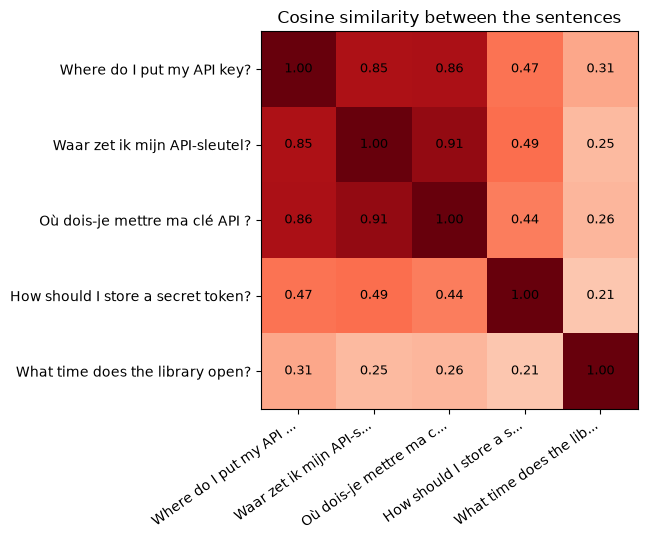

In [4]:
similarity = vectors @ vectors.T   # every sentence against every sentence

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.imshow(similarity, cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(len(sentences)), [s[:22] + "..." for s in sentences], rotation=35, ha="right")
ax.set_yticks(range(len(sentences)), sentences)
for i in range(len(sentences)):
    for j in range(len(sentences)):
        ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Cosine similarity between the sentences")
plt.tight_layout()
plt.show()

The same question in three languages lands close together. *Store a secret token* shares
almost no words with *put my API key* and still lands nearby. The library question is far
from all of them. That is the whole trick: **search by meaning becomes search by
distance**.

---
## Part B, cut the guide into sections and search it

A whole guide is too long to compare with one question: everything would be a bit
similar. So we cut it at its headings. Every section becomes one **chunk**, with the
heading path as its title, so we can quote it later.

In [5]:
def chunk_markdown(path):
    """Cut a Markdown file at its headings. Returns a list of {"source", "title", "text"}."""
    text = Path(path).read_text(encoding="utf-8")
    chunks, headings = [], []
    # Split just before every line that starts with 1 to 4 # signs: those are headings.
    for part in re.split(r"(?m)^(?=#{1,4} )", text):
        match = re.match(r"(#{1,4}) (.+)", part)
        if not match:
            continue
        level, title = len(match.group(1)), match.group(2).strip()
        headings = headings[:level - 1] + [title]        # the path of headings down to here
        body = part[match.end():].strip()
        if len(body) < 40 or title == "Contents":        # skip empty sections and the table of contents
            continue
        chunks.append({"source": Path(path).name, "title": " > ".join(headings[1:] or headings), "text": body})
    return chunks


chunks = chunk_markdown("data/docs/SETUP.md")
print(len(chunks), "chunks\n")
for chunk in chunks[:8]:
    print(f"{chunk['title'][:50]:<52} {len(chunk['text']):>5} characters")

25 chunks

Setup a Python development environment                  70 characters
1. How this works                                     1282 characters
2. Your platform                                       246 characters
2. Your platform > 2.1 Windows: install WSL first      356 characters
2. Your platform > 2.1 Windows: install WSL first      344 characters
2. Your platform > 2.1 Windows: install WSL first      297 characters
2. Your platform > 2.1 Windows: install WSL first      600 characters
2. Your platform > 2.1 Windows: install WSL first      663 characters


Now embed every chunk. EmbeddingGemma was trained with a short label in front of each
text, one for documents and one for questions, and it works best when we use the same
labels. That is a detail of this model, written on its model card, and exactly the kind of
detail worth reading.

In [6]:
def embed_documents(chunks):
    return embed([f"title: {c['title']} | text: {c['text']}" for c in chunks])


def embed_question(question):
    return embed([f"task: search result | query: {question}"])[0]


start = time.time()
chunk_vectors = embed_documents(chunks)
print(f"embedded {len(chunks)} chunks in {time.time() - start:.1f} s")


def search(question, k=3):
    """The k chunks closest in meaning to the question, as (score, chunk) pairs."""
    scores = chunk_vectors @ embed_question(question)     # one similarity per chunk
    best = np.argsort(-scores)[:k]                        # positions of the k highest scores
    return [(float(scores[i]), chunks[i]) for i in best]


for score, chunk in search("VS Code cannot find my packages"):
    print(f"{score:.2f}  {chunk['title']}")

embedded 25 chunks in 0.4 s
0.59  7. Open and run a project
0.56  3. Install VS Code
0.52  3. Install VS Code > 3.1 Extensions


### Against keyword search

The classic alternative counts the words a question shares with each chunk. Watch both on
questions phrased differently from the guide, or written in another language.

In [7]:
def keyword_search(question, k=3):
    """Score each chunk by how many words of the question it contains."""
    words = set(re.findall(r"\w+", question.lower())) - {"the", "a", "i", "my", "do", "to", "is", "how", "what"}
    scores = [len(words & set(re.findall(r"\w+", c["text"].lower()))) for c in chunks]
    best = np.argsort(scores)[::-1][:k]
    return [(scores[i], chunks[i]) for i in best]


for question in ["Waar moet ik mijn projectmap bewaren?",
                 "Comment vérifier que mon installation fonctionne ?",
                 "Where do I put my API key?"]:
    print(question)
    print("   meaning :", search(question, 1)[0][1]["title"])
    print("   keywords:", keyword_search(question, 1)[0][1]["title"])

Waar moet ik mijn projectmap bewaren?
   meaning : 5. Set up Git > 5.3 Create a project folder
   keywords: 11. Official documentation
Comment vérifier que mon installation fonctionne ?
   meaning : 6. Verify your setup
   keywords: 11. Official documentation
Where do I put my API key?
   meaning : 10. API keys
   keywords: 5. Set up Git > 5.4 Keep secrets and clutter out, with .gitignore


Keywords work when the user happens to use the guide's words. Meaning works when they do
not, which is most of the time, and in Brussels it is often a different language.

---
## Part C, answer from the sections

Now the generation step. We give the model the three closest chunks, numbered, and three
rules: answer only from these, cite the number, and say so when the answer is not there.

In [8]:
INSTRUCTIONS = """You answer questions from students about their course documents.
Use only the numbered sources below. After every claim, cite its source like [2].
If the sources do not contain the answer, say exactly: "That is not in the documents, ask your teacher."
Answer in the language of the question, in at most 120 words."""

MIN_SCORE = 0.3   # below this, nothing in the documents is about the question


def answer(question):
    """Retrieve, then generate. Returns the answer text and the sources it was given."""
    found = search(question, k=3)
    if found[0][0] < MIN_SCORE:           # do not even ask the model: nothing relevant was found
        return "That is not in the documents, ask your teacher.", []

    sources = "\n\n".join(f"[{n}] {chunk['title']}\n{chunk['text']}"
                          for n, (score, chunk) in enumerate(found, start=1))
    response = ollama.chat(
        model=CHAT_MODEL,
        messages=[{"role": "system", "content": INSTRUCTIONS},
                  {"role": "user", "content": f"Sources:\n\n{sources}\n\nQuestion: {question}"}],
        options={**OLLAMA_OPTIONS, "temperature": 0},
        think=False,
    )
    return response.message.content, [f"[{n}] {c['title']} ({s:.2f})" for n, (s, c) in enumerate(found, start=1)]


def show(question):
    start = time.time()
    text, sources = answer(question)
    print(f"Q: {question}\n\n{text}\n")
    for line in sources:
        print("  ", line)
    print(f"   {time.time() - start:.1f} s\n")


show("VS Code cannot find my packages, what do I do?")

Q: VS Code cannot find my packages, what do I do?

To fix "it cannot find my packages," follow these steps [1]: Open the project folder itself, never a parent folder. Ensure you have one virtual environment (`.venv`) per project and install dependencies using `uv pip install` [1]. When running code, always use `uv run python main.py` instead of plain `python` to guarantee the correct environment is used [1]. Finally, verify that VS Code has detected your `.venv` and selected it as the interpreter via `Ctrl+Shift+P` > **Python: Select Interpreter** [1].

   [1] 7. Open and run a project (0.61)
   [2] 3. Install VS Code (0.58)
   [3] 3. Install VS Code > 3.1 Extensions (0.53)
   4.2 s



In [9]:
show("Ik heb uv geïnstalleerd maar krijg 'command not found'.")
show("When is the exam?")

Q: Ik heb uv geïnstalleerd maar krijg 'command not found'.

Je krijgt "command not found" omdat je de terminals niet hebt gesloten en een nieuwe geopend na het installeren [1]. De installer voegt `uv` pas toe aan je PATH, en alleen nieuwe terminals lezen dit op [1]. Sluit alle terminalvensters, open er één nieuw en probeer opnieuw met `uv --version` om te controleren of het werkt [1].

   [1] 4. Install uv (0.67)
   [2] 1. How this works (0.49)
   [3] 7. Open and run a project (0.44)
   3.8 s

Q: When is the exam?

That is not in the documents, ask your teacher.

   0.0 s



Three things to notice:

- **It answers in the language of the question**, from a guide written in English
- **The numbers in brackets point at the sources.** A student can open that section and
  check. An answer you can check is worth more than a confident one
- **The exam question never reached the model.** The best match scored below `MIN_SCORE`,
  so the code answered by itself. The cheapest way to stop a model from inventing is to
  not ask it when there is nothing to answer from

---
## Part D, test it

A helpdesk you cannot measure is a helpdesk you cannot improve. The retrieval half is easy
to test: for questions where we know which section holds the answer, does that section
come back in the top three?

In [10]:
# Each question with a word that must appear in the title of the right section.
TESTS = [
    ("How do I install Python on Windows?", "Windows"),
    ("VS Code cannot find my packages", "Open and run"),
    ("Where do I put my API key?", "API keys"),
    ("I get command not found after installing uv", "Install uv"),
    ("Waar moet ik mijn projectmap bewaren?", "project folder"),
    ("Comment vérifier que mon installation fonctionne ?", "Verify"),
    ("My notebook does not show the .venv kernel", "Notebooks"),
    ("Should I commit my .env file?", ".gitignore"),
    ("How do I add scikit-learn to my project?", "Adding packages"),
    ("What does uv actually do?", "How this works"),
]

hits = 0
for question, expected in TESTS:
    titles = [chunk["title"] for _, chunk in search(question, k=3)]
    hit = any(expected in title for title in titles)
    hits += hit
    print(f"{'✓' if hit else '✗'}  {question[:50]:<52} {titles[0][:40]}")
print(f"\nright section in the top 3: {hits} of {len(TESTS)}")

✓  How do I install Python on Windows?                  Setup a Python development environment
✓  VS Code cannot find my packages                      7. Open and run a project
✓  Where do I put my API key?                           10. API keys
✓  I get command not found after installing uv          4. Install uv
✓  Waar moet ik mijn projectmap bewaren?                5. Set up Git > 5.3 Create a project fol
✓  Comment vérifier que mon installation fonctionne ?   6. Verify your setup
✓  My notebook does not show the .venv kernel           8. Notebooks
✓  Should I commit my .env file?                        5. Set up Git > 5.4 Keep secrets and clu
✓  How do I add scikit-learn to my project?             9. Adding packages
✓  What does uv actually do?                            4. Install uv

right section in the top 3: 10 of 10


Write a test like this before you change anything: a different embedding model, bigger or
smaller chunks, another `k`. Then you know whether the change helped, instead of guessing
from two questions you happened to try.

**Exercise D1.** Add three questions of your own to `TESTS`, one in Dutch or French.

**Exercise D2.** Change `MIN_SCORE` to 0.5. Which real questions does the helpdesk now
refuse? What is the right value, and how would you decide it?

---
## Part E, the chat app, and your own documents

In [11]:
import gradio as gr


def chat(message, history):
    """Gradio calls this with the new message and the conversation so far."""
    text, sources = answer(message)
    if sources:
        text += "\n\n---\n*Sources:* " + " · ".join(sources)
    return text


helpdesk_app = gr.ChatInterface(
    chat,
    title="Course helpdesk",
    description="Questions about the setup guide, in English, Dutch or French.",
    examples=["How do I open a notebook in VS Code?", "Waar zet ik mijn API-sleutel?", "When is the exam?"],
)
helpdesk_app.launch(inbrowser=True, inline=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [12]:
helpdesk_app.close()

Closing server running on port: 7860


### Your own documents

Everything above works on any Markdown or text file. Put your own files in `data/docs`:
course notes, a regulation, the README of a project. Then run the cell below and go back
to Part C.

In [13]:
chunks = []
for path in sorted(Path("data/docs").glob("*")):       # every file in the folder
    if path.suffix in (".md", ".txt"):
        new = chunk_markdown(path)
        if not new:                                     # a file without headings: one chunk per paragraph
            paragraphs = [p.strip() for p in path.read_text(encoding="utf-8").split("\n\n") if len(p.strip()) > 40]
            new = [{"source": path.name, "title": f"{path.name}, paragraph {i + 1}", "text": p}
                   for i, p in enumerate(paragraphs)]
        chunks += new
        print(f"{path.name:<30} {len(new)} chunks")

chunk_vectors = embed_documents(chunks)
print("\nready:", len(chunks), "chunks. Go back to Part C, or relaunch the app.")

SETUP.md                       25 chunks



ready: 25 chunks. Go back to Part C, or relaunch the app.


**Exercise E1.** Ask something your documents answer only *partly*. Does the model fill
the gap from its own memory? Look for a claim without a source number.

**Exercise E2.** PDFs are the format most documents really come in. Install `pypdf`
(`uv pip install pypdf`), read a PDF page by page and make one chunk per page.

---
## What to take from this

**The model never read your documents.** It was handed three sections, a few seconds
before answering. Which three is decided by the retrieval step, so most RAG problems are
retrieval problems: the right section never reached the model.

**Sources make answers checkable.** An answer with a section number can be verified in
ten seconds; an answer without one has to be trusted.

**Refusing is a feature.** The best answer to a question your documents do not cover is
*that is not in the documents*. Measure how often it says that, and how often it should.

**Measure the parts you can measure.** Retrieval has a right answer per question, so test
it with a list like `TESTS`. The quality of the written answers is harder: read a sample,
every time something changes.